In [1]:
# checking that the whole pipeline works 
# loss should get close to zero on 10 images
# data --> loss --> optimizer --> loop --> expected 

import sys
sys.path.append("..")

from pathlib import Path 
import torch
from torch import nn 
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt 
from src.dataset import MarsTerrainDataset, build_pairs
from src.unet import UNet 

DATA_DIR = Path(r"C:\data-mars\msl\ncam")
IMG_DIR = DATA_DIR / "images" / "edr"
TRAIN_LBL_DIR = DATA_DIR / "labels" / "train"

all_pairs = build_pairs(IMG_DIR, TRAIN_LBL_DIR)
ds = MarsTerrainDataset(all_pairs[:10], size=128)
loader = DataLoader(ds, batch_size=10, shuffle=False)
imgs, lbls = next(iter(loader))
print(imgs.shape) # should be [10, 1, 128, 128]

torch.Size([10, 1, 128, 128])


In [ ]:
model = UNet()
loss_fn = nn.CrossEntropyLoss(ignore_index=255)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

model.train()
for step in range(200):
    preds = model(imgs)
    loss = loss_fn(preds, lbls)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if step % 10 == 0:
        print(step, loss.item())

# the model memorized the 10 images, doesn't say anything about how the model handles new ones 
# loss 11.11 --> 0.005 

# data → U-Net → loss → training → predictions

0 1.110838770866394
10 0.2982645034790039
20 0.17154596745967865
30 0.10942956060171127
40 0.07150063663721085
50 0.05320689454674721
60 0.036929309368133545
70 0.025923484936356544
80 0.023601578548550606
90 0.018218807876110077
100 0.014358422718942165
110 0.01199242565780878
120 0.010337376967072487
130 0.009064179845154285
140 0.008022928610444069
150 0.00713310344144702
160 0.006398489233106375
170 0.005809476133435965
180 0.0053108856081962585
190 0.004877505358308554


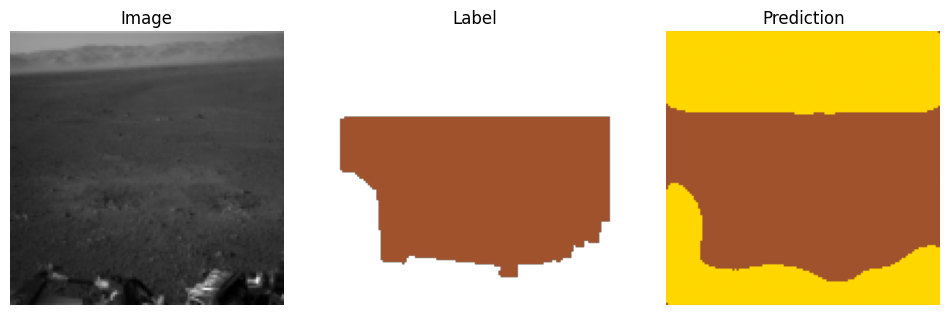

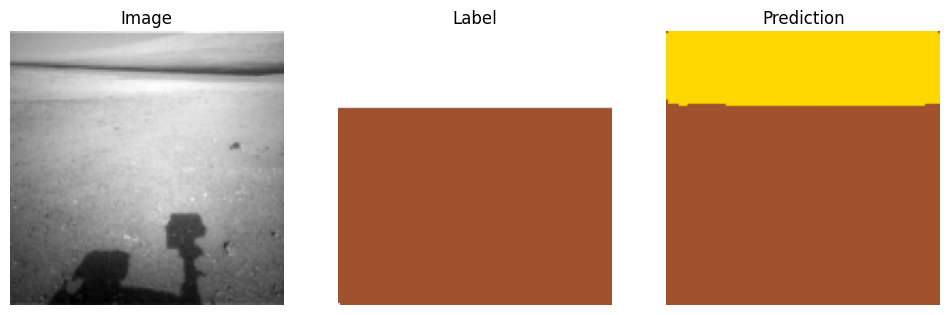

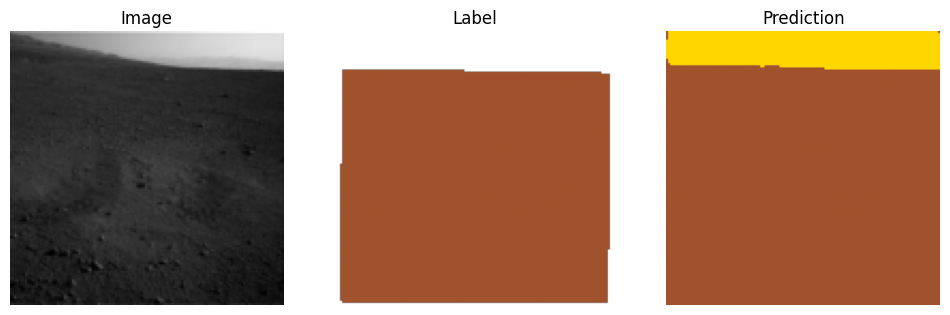

In [4]:
# plot the predictions next to the labels 

import matplotlib.pyplot as plt 
from matplotlib.colors import ListedColormap
import numpy as np 

cmap = ListedColormap(["sienna", "gray", "gold", "red"]) # soil, bedrock, sand, big rock

model.eval()
with torch.no_grad(): # no gradients needed
    preds = model(imgs)
    pred_classes = preds.argmax(dim=1) # turns the 4 class scores per pixel into the predicted class: shape [10, 128, 128]
    # model on imgs, then argmax over classes

# mask the label’s 255s, but not the prediction
for i in [0, 3, 7]:
    lbl_masked = np.ma.masked_equal(lbls[i].numpy(), 255) # label number i 

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(imgs[i, 0], cmap="gray") # image i, drop the channel from the image
    axes[0].set_title("Image")
    axes[1].imshow(lbl_masked, cmap=cmap, vmin=0, vmax=3)
    axes[1].set_title("Label")
    axes[2].imshow(pred_classes[i], cmap=cmap, vmin=0, vmax=3) # prediction i
    axes[2].set_title("Prediction")
    for ax in axes:
        ax.axis("off")
    plt.show()
